# 🌊 Análise temporal de água — Pantanal 2019

Este notebook analisa **12 imagens binárias mensais** (1 = água, 0 = não-água) do Pantanal e gera vários produtos derivados:

| Produto | O que mostra |
|---|---|
| **Frequência** | Quantos meses cada pixel teve água |
| **Classes hidrológicas** | Categoriza pixels: nunca / raro / sazonal / semi-permanente / permanente |
| **Regime cheia × seca** | Predomina cheia (dez–mai) ou seca (jun–nov)? |
| **Estação predominante** | Qual estação concentra mais alagamento |
| **Persistência contínua** | Maior sequência ininterrupta de meses alagados |
| **Eventos de inundação/seca** | Quantas vezes o pixel mudou de estado |
| **Primeiro / último mês** | Quando começou e terminou o período hídrico |
| **Hidrograma** | Área alagada (km²) mês a mês |

> **Pré-requisito:** os 12 arquivos `jan.tif`, `fev.tif`, ..., `dez.tif` na mesma pasta, todos com mesma projeção, resolução e extensão.

---

## 1. Instalação e imports

O Colab já vem com `numpy`, `matplotlib` e `pandas`. Precisamos instalar `rasterio` (leitura de GeoTIFF) e `imageio` (pra fazer o GIF animado no fim).

In [ ]:
!pip install rasterio imageio --quiet

In [ ]:
import os
import numpy as np
import rasterio
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches

# Aumenta o tamanho default das figuras
plt.rcParams['figure.dpi'] = 100

## 2. Entrada dos dados

Você tem **3 opções** pra deixar os 12 GeoTIFFs disponíveis no Colab:

### Opção A — Upload direto (mais simples, mas lento se forem muitos MB)
Use a célula abaixo. Vai abrir um seletor de arquivos do navegador. Selecione os 12 .tif de uma vez.

### Opção B — Google Drive (recomendada se for usar várias vezes)
Monte seu Drive e aponte para a pasta com os arquivos.

### Opção C — Rodar localmente
Se você não usa o Colab, basta apontar `PASTA_ENTRADA` para o caminho da pasta na sua máquina.

**▼ Opção A — Upload manual** (descomente para usar)

In [ ]:
# from google.colab import files
# os.makedirs('/content/dados', exist_ok=True)
# uploaded = files.upload()  # selecione os 12 .tif
# for nome in uploaded:
  #    os.rename(nome, f'/content/dados/{nome}')
# PASTA_ENTRADA = '/content/dados'

Saving ago.tif to ago.tif
Saving set.tif to set.tif
Saving jul.tif to jul.tif
Saving abr.tif to abr.tif
Saving out.tif to out.tif
Saving jan.tif to jan.tif
Saving mar.tif to mar.tif
Saving mai.tif to mai.tif
Saving fev.tif to fev.tif
Saving jun.tif to jun.tif
Saving nov.tif to nov.tif
Saving dez.tif to dez.tif


**▼ Opção B — Google Drive** (descomente para usar)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
PASTA_ENTRADA = '/content/drive/MyDrive/Pantanal/2019'  # ajuste

Mounted at /content/drive


**▼ Opção C — Caminho local** (assumindo que os arquivos já estão acessíveis)

In [ ]:
PASTA_ENTRADA = '/content/drive/MyDrive/Pantanal/2019'   # ajuste se precisar
PASTA_SAIDA   = '/content/drive/MyDrive/Pantanal/2019/resultados'
os.makedirs(PASTA_SAIDA, exist_ok=True)

# Confere se está tudo lá
arquivos = sorted(os.listdir(PASTA_ENTRADA))
print(f'{len(arquivos)} arquivos na pasta:')
for a in arquivos[:5]:
   print(f'  {a}')
print('  ...')

1 arquivos na pasta:
  resultados
  ...


## 3. Leitura dos rasters → stack temporal 3D

A ideia central de toda a análise é **empilhar** os 12 rasters num único array tridimensional:

```
stack.shape = (12, altura, largura)
   ▲           ▲    ▲       ▲
   │           │    │       └── colunas (longitude)
   │           │    └────────── linhas   (latitude)
   │           └─────────────── tempo (meses 0=jan ... 11=dez)
   └─────────────────────────── numpy array 3D
```

Com isso, qualquer operação temporal vira uma operação no **eixo 0**. Por exemplo:
- `stack.sum(axis=0)` → frequência (soma ao longo do tempo)
- `stack.mean(axis=0)` → fração média de tempo com água
- `stack[5]` → o raster do mês de junho

Esse é o pulo do gato pra trabalhar com séries temporais de imagens em Python.

### Diagnóstico — verificando se os rasters estão alinhados

Antes de empilhar, é boa prática conferir se os 12 rasters têm exatamente o mesmo tamanho. Pequenas diferenças de bordas (poucos pixels) são comuns e quebram o `np.stack`. Se acontecer, o código abaixo **reprojeta automaticamente** os rasters discrepantes pra grade do primeiro mês.

In [ ]:
from rasterio.warp import reproject, Resampling

MESES_ARQ = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun',
             'jul', 'ago', 'set', 'out', 'nov', 'dez']
MESES_NOM = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
             'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

# Diagnóstico: imprime tamanho de cada raster
print('Verificando dimensões dos rasters:')
for mes in MESES_ARQ:
    with rasterio.open(os.path.join(PASTA_ENTRADA, f'{mes}.tif')) as src:
        print(f'  {mes}: {src.height} x {src.width}  |  bounds: {src.bounds}')
print()

# Usa o primeiro mês (jan) como GRADE DE REFERÊNCIA
caminho_ref = os.path.join(PASTA_ENTRADA, f'{MESES_ARQ[0]}.tif')
with rasterio.open(caminho_ref) as ref:
    perfil        = ref.profile.copy()
    altura        = ref.height
    largura       = ref.width
    transform_ref = ref.transform
    crs_ref       = ref.crs

stack = []
for mes in MESES_ARQ:
    caminho = os.path.join(PASTA_ENTRADA, f'{mes}.tif')
    with rasterio.open(caminho) as src:
        # Caso 1: já está alinhado -> lê direto
        mesma_grade = ((src.height, src.width) == (altura, largura)
                       and src.transform == transform_ref)
        if mesma_grade:
            img = src.read(1)
            if src.nodata is not None:
                img = np.where(img == src.nodata, 0, img)
            img = (img == 1).astype(np.uint8)
        # Caso 2: grade diferente -> reprojeta pra grade de referência
        else:
            print(f'  ↻ reprojetando {mes}: {src.height}x{src.width} → {altura}x{largura}')
            destino = np.zeros((altura, largura), dtype=np.uint8)
            reproject(
                source=rasterio.band(src, 1),
                destination=destino,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform_ref,
                dst_crs=crs_ref,
                resampling=Resampling.nearest,  # NEAREST! Dados categóricos nunca interpolam
            )
            img = (destino == 1).astype(np.uint8)
        stack.append(img)

stack = np.stack(stack)  # agora vai funcionar — todos têm a mesma forma
print(f'\nStack shape: {stack.shape}')
print(f'CRS: {perfil["crs"]}')
print(f'Tamanho do pixel: {abs(perfil["transform"][0]):.1f} x {abs(perfil["transform"][4]):.1f} m')

Verificando dimensões dos rasters:
  jan: 16505 x 21889  |  bounds: BoundingBox(left=462580.0, bottom=7825940.0, right=681470.0, top=7990990.0)
  fev: 16505 x 21889  |  bounds: BoundingBox(left=462580.0, bottom=7825940.0, right=681470.0, top=7990990.0)
  mar: 16505 x 21889  |  bounds: BoundingBox(left=462580.0, bottom=7825940.0, right=681470.0, top=7990990.0)
  abr: 16505 x 21889  |  bounds: BoundingBox(left=462580.0, bottom=7825940.0, right=681470.0, top=7990990.0)
  mai: 16505 x 21889  |  bounds: BoundingBox(left=462580.0, bottom=7825940.0, right=681470.0, top=7990990.0)
  jun: 16505 x 21889  |  bounds: BoundingBox(left=462580.0, bottom=7825940.0, right=681470.0, top=7990990.0)
  jul: 16505 x 21889  |  bounds: BoundingBox(left=462580.0, bottom=7825940.0, right=681470.0, top=7990990.0)
  ago: 16505 x 21889  |  bounds: BoundingBox(left=462580.0, bottom=7825940.0, right=681470.0, top=7990990.0)
  set: 16690 x 23242  |  bounds: BoundingBox(left=-57.35698173338939, bottom=-19.661785949637

**Por que `Resampling.nearest`?** Como os valores são **categóricos** (água/não-água, 0 ou 1), nunca podemos interpolar. `nearest` pega o valor do pixel mais próximo na fonte e preserva 0s e 1s puros. Se usasse `bilinear` ou `cubic`, apareceriam valores tipo 0.37 que quebrariam tudo dali pra frente.

### Visualizando os 12 meses

Antes de qualquer análise, sempre vale dar uma olhada nos dados. Cada subplot é um mês:

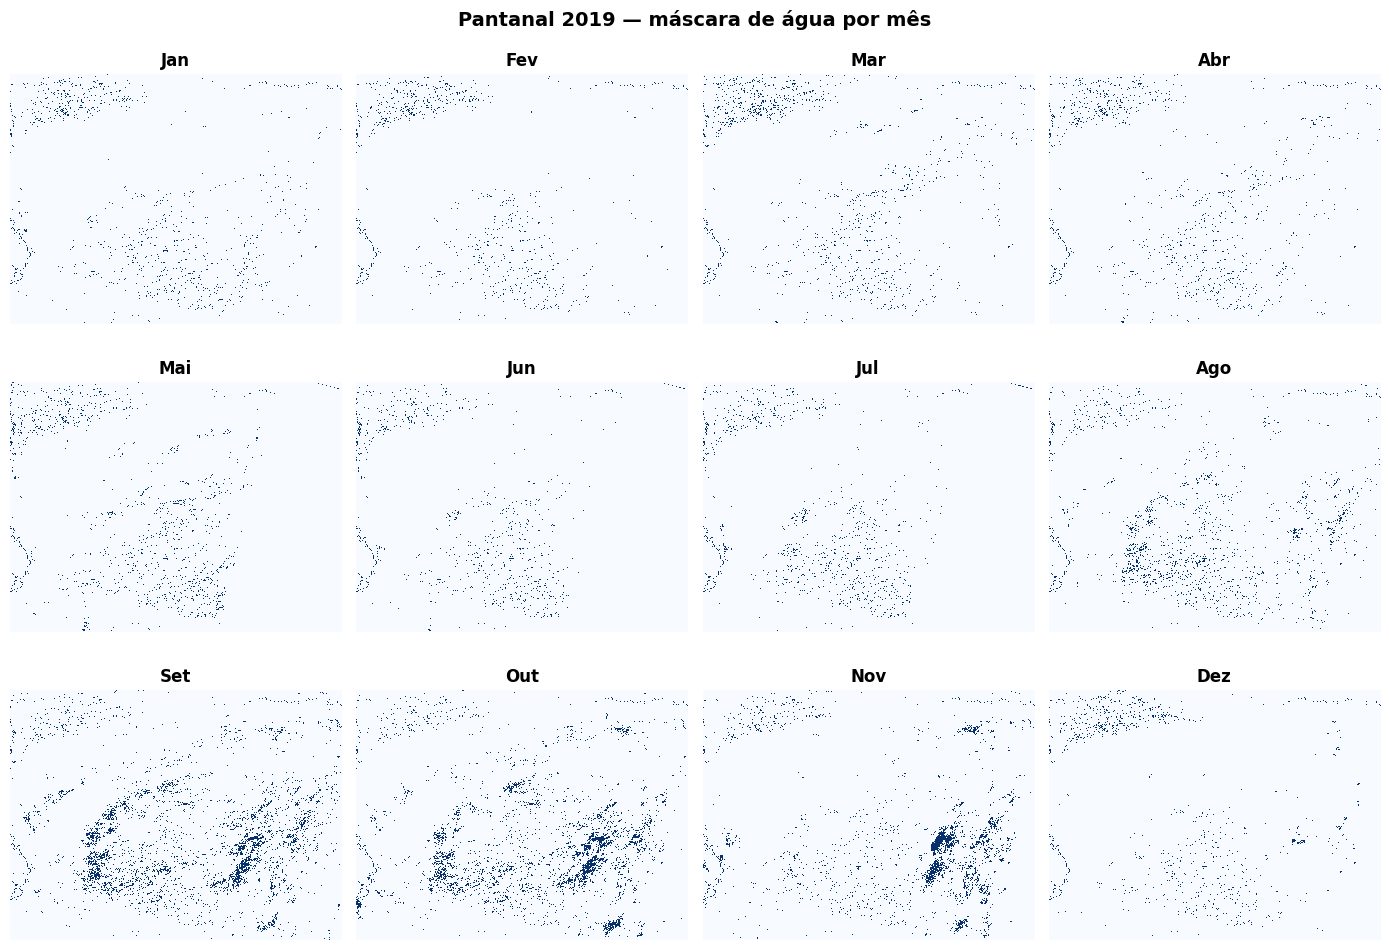

In [ ]:
import os
import matplotlib.pyplot as plt # Adicionando a importação do pyplot
import numpy as np # Necessário para np.stack e operações com arrays
import rasterio # Necessário para ler GeoTIFFs
from rasterio.warp import reproject, Resampling # Necessário para reprojeção

# Re-definição de variáveis necessárias para criar 'stack' (originalmente em células anteriores)
PASTA_ENTRADA = '/content/drive/MyDrive/Pantanal/2019' # Caminho da pasta de entrada
PASTA_SAIDA   = '/content/drive/MyDrive/Pantanal/2019/resultados'
os.makedirs(PASTA_SAIDA, exist_ok=True)

MESES_ARQ = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun',
             'jul', 'ago', 'set', 'out', 'nov', 'dez']
MESES_NOM = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
             'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

# Recriação da variável 'stack' (código copiado de célula 40c25a5a para autossuficiência)
caminho_ref = os.path.join(PASTA_ENTRADA, f'{MESES_ARQ[0]}.tif')
with rasterio.open(caminho_ref) as ref:
    perfil        = ref.profile.copy()
    altura        = ref.height
    largura       = ref.width
    transform_ref = ref.transform
    crs_ref       = ref.crs

stack = []
for mes in MESES_ARQ:
    caminho = os.path.join(PASTA_ENTRADA, f'{mes}.tif')
    with rasterio.open(caminho) as src:
        mesma_grade = ((src.height, src.width) == (altura, largura)
                       and src.transform == transform_ref)
        if mesma_grade:
            img = src.read(1)
            if src.nodata is not None:
                img = np.where(img == src.nodata, 0, img)
            img = (img == 1).astype(np.uint8)
        else:
            # print(f'  ↻ reprojetando {mes}: {src.height}x{src.width} → {altura}x{largura}') # Comentado para evitar saída excessiva
            destino = np.zeros((altura, largura), dtype=np.uint8)
            reproject(
                source=rasterio.band(src, 1),
                destination=destino,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform_ref,
                dst_crs=crs_ref,
                resampling=Resampling.nearest,
            )
            img = (destino == 1).astype(np.uint8)
        stack.append(img)
stack = np.stack(stack)
# Fim da recriação da variável 'stack'

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(stack[i], cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(MESES_NOM[i], fontweight='bold')
    ax.axis('off')
fig.suptitle('Pantanal 2019 — máscara de água por mês', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PASTA_SAIDA}/fig_mapas_mensais.png', dpi=150, bbox_inches='tight')
plt.show()

**O que observar:** dá pra notar visualmente o pulso de inundação típico do Pantanal — área alagada cresce no verão (cheia) e encolhe no inverno (seca). Vamos quantificar isso a seguir.

## 4. Função utilitária para salvar GeoTIFFs

Vamos salvar cada produto como GeoTIFF mantendo o georreferenciamento (pra abrir no QGIS/ArcGIS depois). Como é a mesma operação várias vezes, vale uma funçãozinha:

In [ ]:
def salvar_raster(arr, nome, dtype='uint8'):
    """Salva array como GeoTIFF na PASTA_SAIDA, herdando o perfil do raster original."""
    p = perfil.copy()
    p.update(dtype=dtype, count=1, compress='lzw')  # lzw deixa o arquivo bem menor
    caminho = os.path.join(PASTA_SAIDA, nome)
    with rasterio.open(caminho, 'w', **p) as dst:
        dst.write(arr.astype(dtype), 1)
    print(f'  ✓ {nome}')

## 5. Frequência temporal de água

**Pergunta:** *quantos meses do ano cada pixel teve água?*

Como `stack` só tem 0s e 1s, somar ao longo do eixo do tempo dá direto o número de meses com água:

$$\text{freq}(i,j) = \sum_{t=0}^{11} \text{stack}[t, i, j]$$

O resultado é um único raster 2D com valores de **0 (nunca) a 12 (sempre)**.

Frequência mínima: 0  |  máxima: 12
Pixels com água em algum mês: 28,169,449
  ✓ frequencia_agua.tif


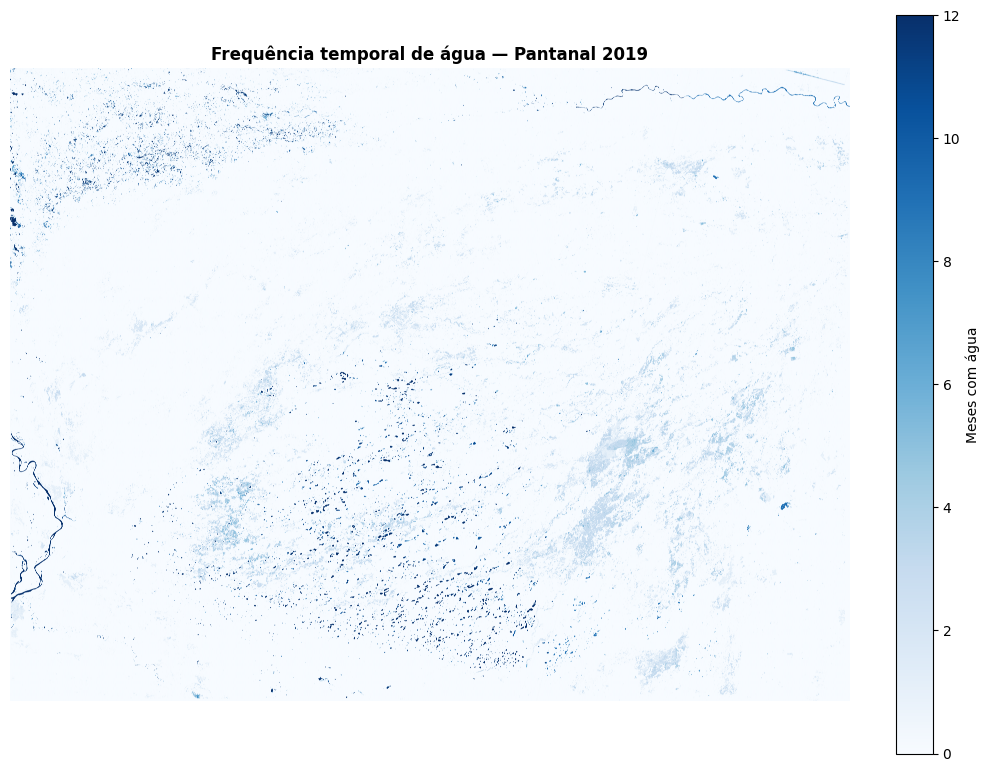

In [ ]:
import os
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
import matplotlib.pyplot as plt # Adicionando a importação do pyplot

# Re-definição de variáveis e recriação de 'stack' (código copiado de células anteriores para autossuficiência)
PASTA_ENTRADA = '/content/drive/MyDrive/Pantanal/2019'
PASTA_SAIDA   = '/content/drive/MyDrive/Pantanal/2019/resultados'
os.makedirs(PASTA_SAIDA, exist_ok=True)

MESES_ARQ = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun',
             'jul', 'ago', 'set', 'out', 'nov', 'dez']
MESES_NOM = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
             'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

# Usa o primeiro mês (jan) como GRADE DE REFERÊNCIA
caminho_ref = os.path.join(PASTA_ENTRADA, f'{MESES_ARQ[0]}.tif')
with rasterio.open(caminho_ref) as ref:
    perfil        = ref.profile.copy()
    altura        = ref.height
    largura       = ref.width
    transform_ref = ref.transform
    crs_ref       = ref.crs

stack = []
for mes in MESES_ARQ:
    caminho = os.path.join(PASTA_ENTRADA, f'{mes}.tif')
    with rasterio.open(caminho) as src:
        mesma_grade = ((src.height, src.width) == (altura, largura)
                       and src.transform == transform_ref)
        if mesma_grade:
            img = src.read(1)
            if src.nodata is not None:
                img = np.where(img == src.nodata, 0, img)
            img = (img == 1).astype(np.uint8)
        else:
            destino = np.zeros((altura, largura), dtype=np.uint8)
            reproject(
                source=rasterio.band(src, 1),
                destination=destino,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform_ref,
                dst_crs=crs_ref,
                resampling=Resampling.nearest,
            )
            img = (destino == 1).astype(np.uint8)
        stack.append(img)
stack = np.stack(stack)
# Fim da recriação da variável 'stack'

# Definição da função salvar_raster, que foi reportada como executada mas pode não estar acessível
def salvar_raster(arr, nome, dtype='uint8'):
    """Salva array como GeoTIFF na PASTA_SAIDA, herdando o perfil do raster original."""
    p = perfil.copy()
    p.update(dtype=dtype, count=1, compress='lzw')  # lzw deixa o arquivo bem menor
    caminho = os.path.join(PASTA_SAIDA, nome)
    with rasterio.open(caminho, 'w', **p) as dst:
        dst.write(arr.astype(dtype), 1)
    print(f'  ✓ {nome}')

freq = stack.sum(axis=0).astype(np.uint8)

print(f'Frequência mínima: {freq.min()}  |  máxima: {freq.max()}')
print(f'Pixels com água em algum mês: {(freq > 0).sum():,}')

salvar_raster(freq, 'frequencia_agua.tif')

# Visualização
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(freq, cmap='Blues', vmin=0, vmax=12)
plt.colorbar(im, ax=ax, label='Meses com água', fraction=0.04)
ax.set_title('Frequência temporal de água — Pantanal 2019', fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Classes hidrológicas

Em cima da frequência, é útil agrupar pixels em **classes interpretáveis**. Os limiares são adaptáveis — esses são razoáveis pra wetlands:

| Classe | Frequência | Interpretação |
|---:|:---:|:---|
| 0 | 0 meses | Nunca alagado (terra firme) |
| 1 | 1–2 meses | Inundação rara/efêmera |
| 2 | 3–6 meses | **Sazonal** (típico de várzea) |
| 3 | 7–10 meses | Semi-permanente |
| 4 | 11–12 meses | Corpo d'água permanente |

  ✓ classes_hidrologicas.tif


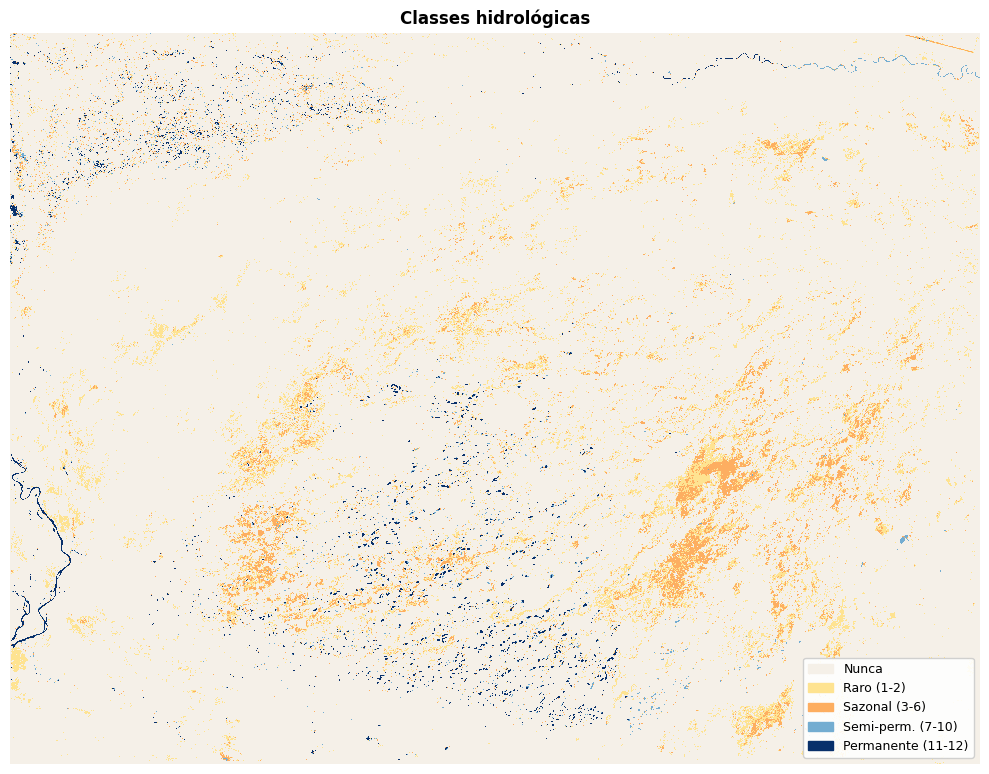

  Nunca                  333,108,496 pixels  ( 92.2 %)
  Raro (1-2)             17,505,528 pixels  (  4.8 %)
  Sazonal (3-6)           7,553,286 pixels  (  2.1 %)
  Semi-perm. (7-10)       1,154,827 pixels  (  0.3 %)
  Permanente (11-12)      1,955,808 pixels  (  0.5 %)


In [ ]:
classes = np.zeros_like(freq)
classes[(freq >= 1)  & (freq <= 2)]  = 1
classes[(freq >= 3)  & (freq <= 6)]  = 2
classes[(freq >= 7)  & (freq <= 10)] = 3
classes[ freq >= 11]                 = 4

salvar_raster(classes, 'classes_hidrologicas.tif')

# Visualização com legenda categórica
cores   = ['#f5f0e8', '#fee391', '#fdae61', '#74add1', '#08306b']
rotulos = ['Nunca', 'Raro (1-2)', 'Sazonal (3-6)',
           'Semi-perm. (7-10)', 'Permanente (11-12)']
cmap = ListedColormap(cores)
norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), cmap.N)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(classes, cmap=cmap, norm=norm, interpolation='nearest')
handles = [mpatches.Patch(color=c, label=r) for c, r in zip(cores, rotulos)]
ax.legend(handles=handles, loc='lower right', fontsize=9, framealpha=0.9)
ax.set_title('Classes hidrológicas', fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PASTA_SAIDA}/fig_classes.png', dpi=150, bbox_inches='tight')
plt.show()

# Tabela com nº de pixels por classe
for i, r in enumerate(rotulos):
    n = (classes == i).sum()
    print(f'  {r:<22} {n:>10,} pixels  ({100*n/classes.size:5.1f} %)')

## 7. Regime cheia × seca

Pro Pantanal, a divisão em **estações astronômicas** (verão/outono/inverno/primavera) é menos informativa que a divisão hidrológica:

- **Cheia**: dezembro a maio (chuvas concentradas, pulso de inundação)
- **Seca**: junho a novembro (recessão das águas)

Para cada pixel, comparamos quantos meses tiveram água em cada período:

  ✓ regime_cheia_seca.tif


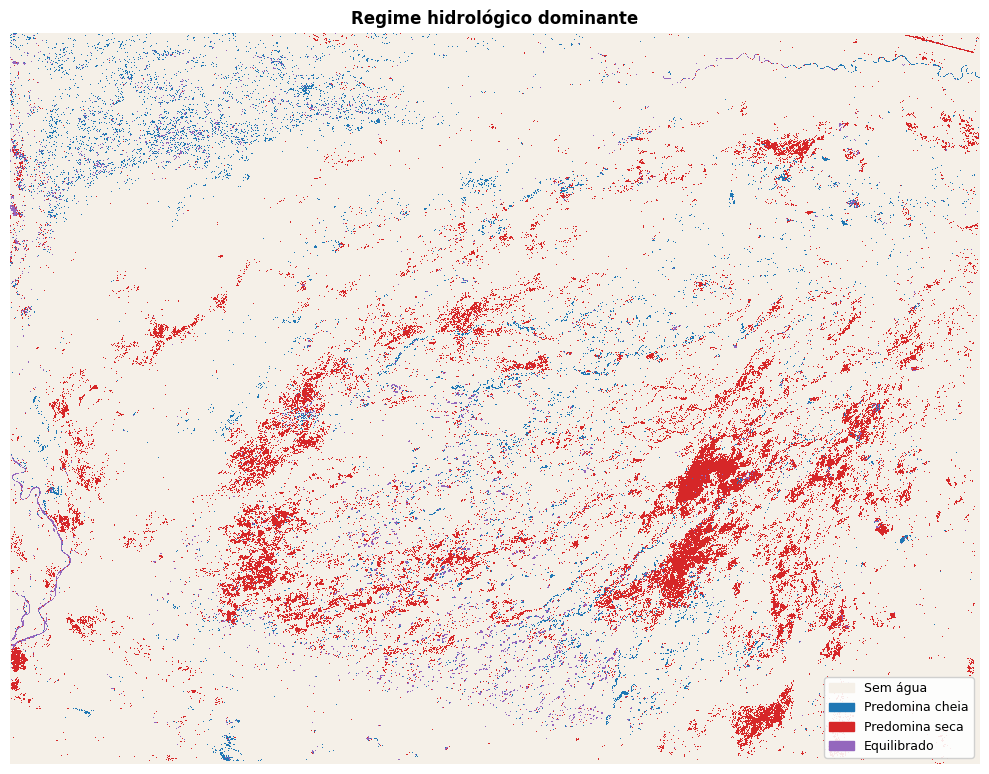

In [ ]:
# Índices dos meses (lembrando que jan=0, fev=1, ..., dez=11)
idx_cheia = [11, 0, 1, 2, 3, 4]   # dez, jan, fev, mar, abr, mai
idx_seca  = [5, 6, 7, 8, 9, 10]   # jun, jul, ago, set, out, nov

agua_cheia = stack[idx_cheia].sum(axis=0)
agua_seca  = stack[idx_seca].sum(axis=0)

regime = np.zeros_like(freq)
regime[agua_cheia >  agua_seca] = 1   # predomina cheia
regime[agua_seca  >  agua_cheia] = 2  # predomina seca
regime[(agua_cheia == agua_seca) & (freq > 0)] = 3  # equilibrado

salvar_raster(regime, 'regime_cheia_seca.tif')

# Visualização
cores_reg = ['#f5f0e8', '#1f77b4', '#d62728', '#9467bd']
rotulos_reg = ['Sem água', 'Predomina cheia', 'Predomina seca', 'Equilibrado']
cmap = ListedColormap(cores_reg)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(regime, cmap=cmap, vmin=0, vmax=3, interpolation='nearest')
handles = [mpatches.Patch(color=c, label=r) for c, r in zip(cores_reg, rotulos_reg)]
ax.legend(handles=handles, loc='lower right', fontsize=9, framealpha=0.9)
ax.set_title('Regime hidrológico dominante', fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

## 8. Estação predominante (4 estações)

Para quem quer manter a divisão clássica em verão/outono/inverno/primavera (hemisfério sul), o código abaixo faz isso. Atribui a cada pixel a estação que concentrou mais meses com água. **`np.argmax`** sobre o eixo das estações faz o trabalho pesado:

  ✓ estacao_predominante.tif


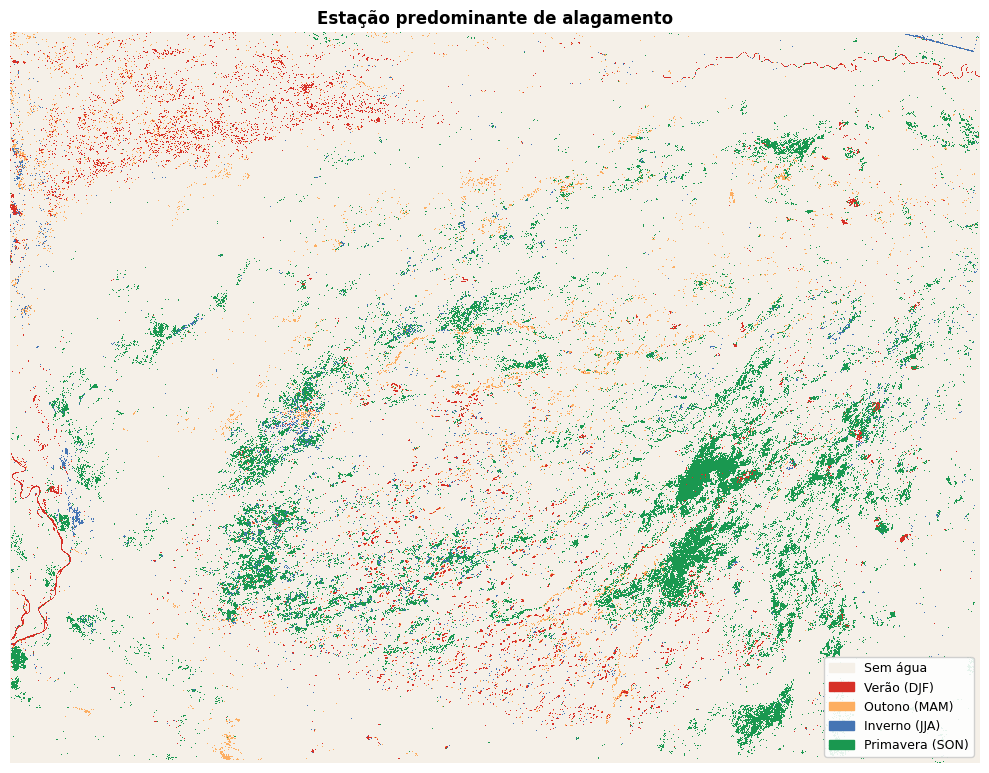


  Sem água           333,108,496 pixels  ( 92.2 %)
  Verão (DJF)         4,326,383 pixels  (  1.2 %)
  Outono (MAM)        3,690,534 pixels  (  1.0 %)
  Inverno (JJA)       2,232,526 pixels  (  0.6 %)
  Primavera (SON)    17,920,006 pixels  (  5.0 %)


In [ ]:
# Índices dos meses por estação (hemisfério sul)
verao     = [11, 0, 1]   # dez, jan, fev
outono    = [2, 3, 4]    # mar, abr, mai
inverno   = [5, 6, 7]    # jun, jul, ago
primavera = [8, 9, 10]   # set, out, nov

# Empilha as 4 contagens em um array (4, H, W)
contagens = np.stack([
    stack[verao].sum(axis=0),
    stack[outono].sum(axis=0),
    stack[inverno].sum(axis=0),
    stack[primavera].sum(axis=0),
])

# argmax retorna o índice da estação com mais meses
# +1 pra ficar 1=verão, 2=outono, 3=inverno, 4=primavera (e 0 fica reservado pra "sem água")
tem_agua = contagens.sum(axis=0) > 0
estacao = np.where(tem_agua, contagens.argmax(axis=0) + 1, 0).astype(np.uint8)

salvar_raster(estacao, 'estacao_predominante.tif')

# Visualização
cores_est   = ['#f5f0e8', '#d73027', '#fdae61', '#4575b4', '#1a9850']
rotulos_est = ['Sem água', 'Verão (DJF)', 'Outono (MAM)',
               'Inverno (JJA)', 'Primavera (SON)']
cmap_est = ListedColormap(cores_est)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(estacao, cmap=cmap_est, vmin=0, vmax=4, interpolation='nearest')
handles = [mpatches.Patch(color=c, label=r) for c, r in zip(cores_est, rotulos_est)]
ax.legend(handles=handles, loc='lower right', fontsize=9, framealpha=0.9)
ax.set_title('Estação predominante de alagamento', fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PASTA_SAIDA}/fig_estacao.png', dpi=150, bbox_inches='tight')
plt.show()

# Tabela com nº de pixels por estação
print()
for i, r in enumerate(rotulos_est):
    n = (estacao == i).sum()
    print(f'  {r:<18} {n:>10,} pixels  ({100*n/estacao.size:5.1f} %)')

## 9. Persistência contínua — a sacada vetorizada ⚡

**Pergunta:** *qual é a maior sequência ininterrupta de meses com água em cada pixel?*

Exemplo de série de um pixel: `[0,1,1,1,0,1,1,0,0,0,0,0]` → maior sequência = **3 meses**.

A solução ingênua seria um loop pixel a pixel. **Não faça isso!** Para um raster de 5000×5000 isso pode levar horas.

### O truque

A cada passo de tempo, mantemos um contador `atual` da sequência em curso e atualizamos um `maior` global. A mágica é a expressão:

```python
atual = (atual + 1) * stack[t]
```

- Se `stack[t] == 1` (água): `(atual + 1) * 1 = atual + 1` → incrementa
- Se `stack[t] == 0` (seco): `(atual + 1) * 0 = 0` → **zera** automaticamente

E como `atual` e `stack[t]` são arrays inteiros, isso roda **em paralelo pra todos os pixels de uma vez**. Fica ~1000× mais rápido que o loop pixel-a-pixel.

  ✓ persistencia_continua.tif


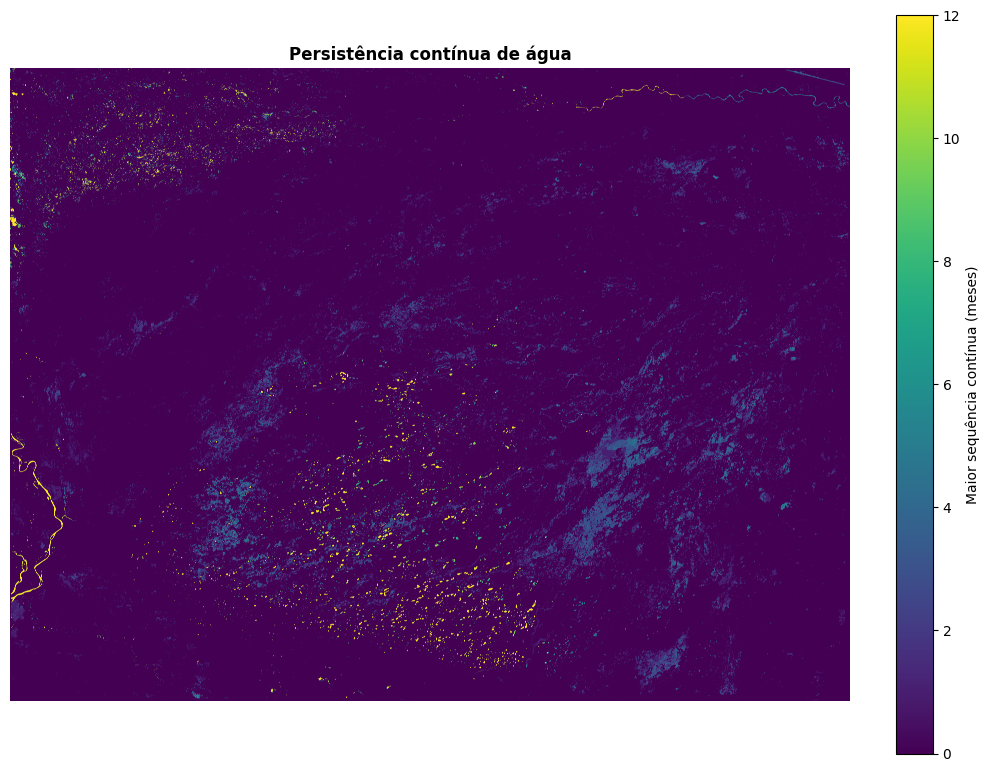

Persistência média: 2.7 meses
Persistência máxima: 12 meses


In [ ]:
atual = np.zeros(stack.shape[1:], dtype=np.uint8)  # contador da sequência em curso
maior = np.zeros_like(atual)                       # melhor sequência até agora

for t in range(12):
    atual = (atual + 1) * stack[t]   # incrementa onde tem água, zera onde não tem
    maior = np.maximum(maior, atual) # atualiza o melhor

persistencia = maior

salvar_raster(persistencia, 'persistencia_continua.tif')

# Visualização
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(persistencia, cmap='viridis', vmin=0, vmax=12)
plt.colorbar(im, ax=ax, label='Maior sequência contínua (meses)', fraction=0.04)
ax.set_title('Persistência contínua de água', fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

print(f'Persistência média: {persistencia[persistencia > 0].mean():.1f} meses')
print(f'Persistência máxima: {persistencia.max()} meses')

## 10. Eventos de inundação e seca

**Pergunta:** *quantas vezes o pixel mudou de estado durante o ano?*

Cada vez que um pixel **alaga** (passa de 0 para 1), conta como um evento de inundação. Cada vez que **seca** (passa de 1 para 0), conta como um evento de seca.

`np.diff` faz a diferença entre meses consecutivos:
- `+1` = entrou na água
- `-1` = saiu da água
-  `0` = não mudou

  ✓ eventos_inundacao.tif
  ✓ eventos_seca.tif


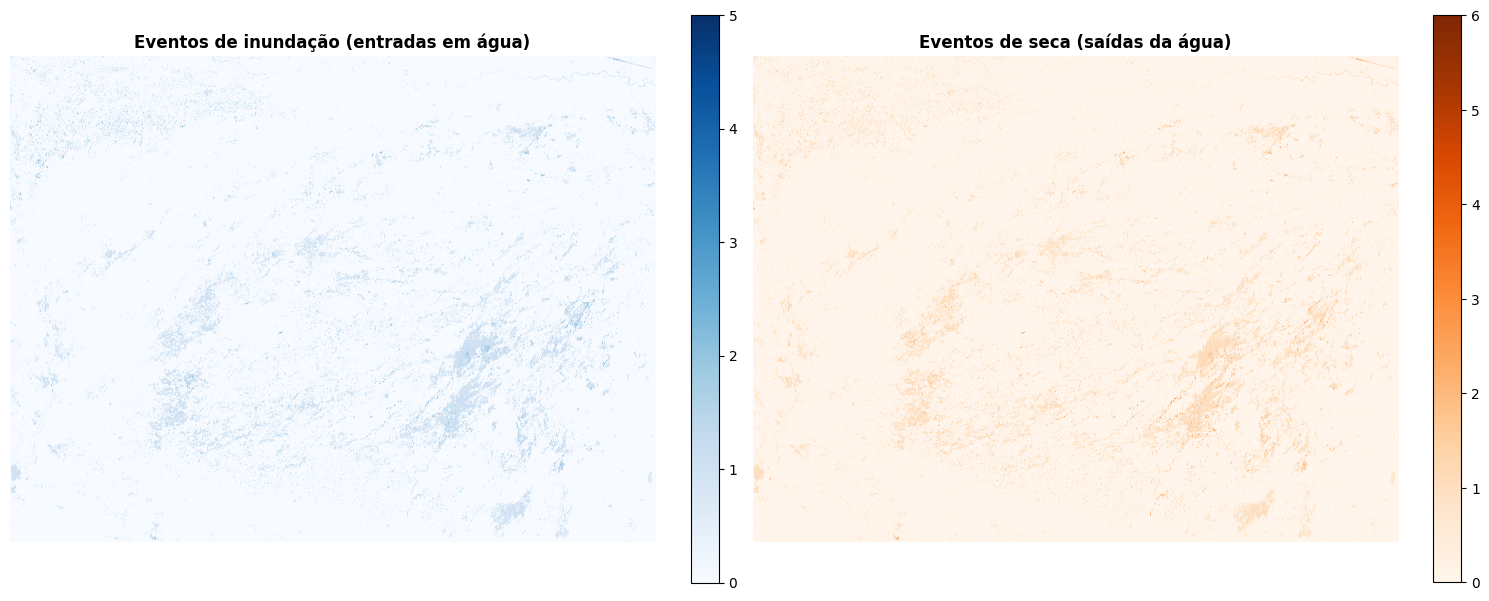

In [ ]:
diff = np.diff(stack.astype(np.int8), axis=0)  # shape: (11, H, W)

eventos_inund = (diff ==  1).sum(axis=0).astype(np.uint8)
eventos_seca  = (diff == -1).sum(axis=0).astype(np.uint8)

salvar_raster(eventos_inund, 'eventos_inundacao.tif')
salvar_raster(eventos_seca,  'eventos_seca.tif')

# Visualização lado a lado
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

im0 = axes[0].imshow(eventos_inund, cmap='Blues', vmin=0, vmax=eventos_inund.max())
axes[0].set_title('Eventos de inundação (entradas em água)', fontweight='bold')
plt.colorbar(im0, ax=axes[0], fraction=0.04)
axes[0].axis('off')

im1 = axes[1].imshow(eventos_seca, cmap='Oranges', vmin=0, vmax=eventos_seca.max())
axes[1].set_title('Eventos de seca (saídas da água)', fontweight='bold')
plt.colorbar(im1, ax=axes[1], fraction=0.04)
axes[1].axis('off')

plt.tight_layout()
plt.show()

**Interpretação:** pixels com **muitos eventos** indicam zonas de **borda dinâmica** do Pantanal — áreas que oscilam entre alagado e seco várias vezes durante o ano. Já pixels com 0 ou 1 evento são estáveis (seja sempre secos, sempre alagados, ou com um único pulso anual).

## 11. Primeiro mês, último mês e duração

**Pergunta:** *quando começa e termina o período hídrico de cada pixel?*

`np.argmax` num array booleano retorna o **índice do primeiro `True`**. Pra achar o último, basta inverter o stack no tempo.

⚠️ **Atenção:** "duração" aqui é diferente de "frequência":
- **Frequência** = total de meses com água (pode ter buracos)
- **Duração** = último mês − primeiro mês + 1 (inclui possíveis buracos no meio)

  ✓ primeiro_mes.tif
  ✓ ultimo_mes.tif
  ✓ duracao_periodo.tif


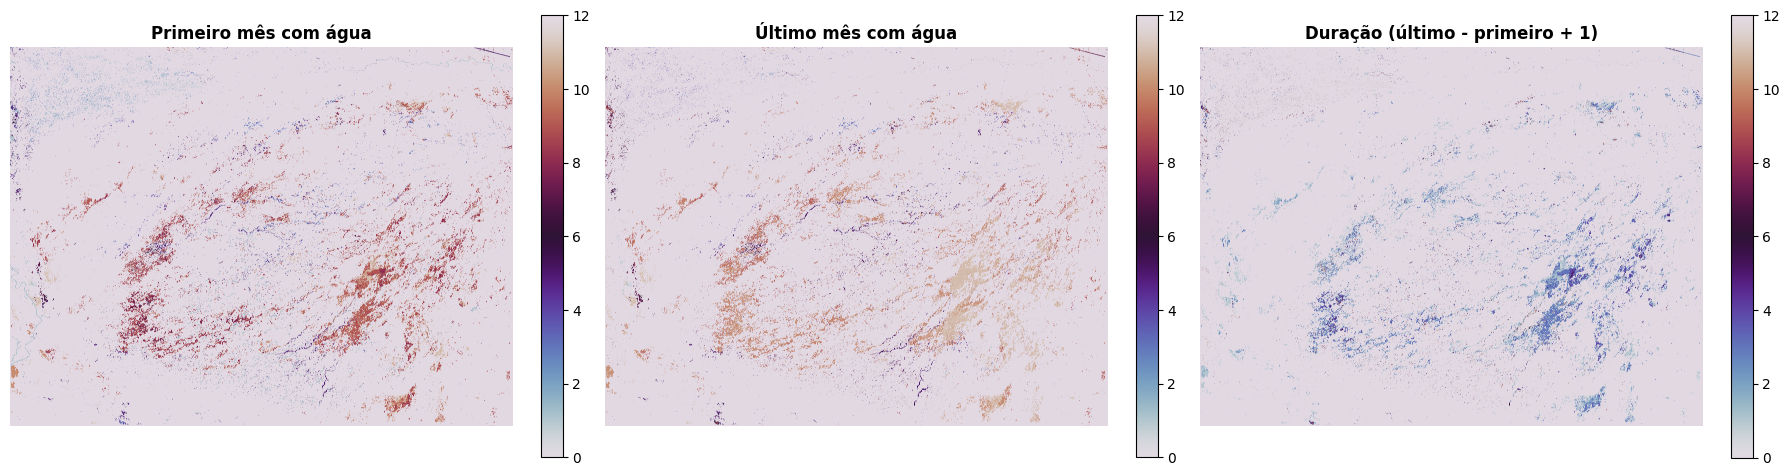

In [ ]:
teve_agua = stack.any(axis=0)

primeiro = stack.argmax(axis=0).astype(np.uint8) + 1
primeiro[~teve_agua] = 0   # pixels sem água ficam com 0

# Pra achar o último, invertemos no tempo: stack[::-1]
ultimo = (12 - stack[::-1].argmax(axis=0)).astype(np.uint8)
ultimo[~teve_agua] = 0

duracao = np.where(teve_agua, ultimo - primeiro + 1, 0).astype(np.uint8)

salvar_raster(primeiro, 'primeiro_mes.tif')
salvar_raster(ultimo,   'ultimo_mes.tif')
salvar_raster(duracao,  'duracao_periodo.tif')

# Visualização
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, dado, titulo in zip(
    axes,
    [primeiro, ultimo, duracao],
    ['Primeiro mês com água', 'Último mês com água', 'Duração (último - primeiro + 1)']
):
    im = ax.imshow(dado, cmap='twilight', vmin=0, vmax=12)
    ax.set_title(titulo, fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.04)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 12. Hidrograma — área alagada por mês

**Pergunta:** *quanto da área total estava alagada em cada mês?*

Esse é provavelmente o gráfico mais importante pra interpretar a dinâmica. Pegamos a área de cada pixel (em m², usando a resolução do raster) e multiplicamos pelo número de pixels alagados em cada mês:

In [ ]:
# Tamanho do pixel em m
res_x = abs(perfil['transform'][0])
res_y = abs(perfil['transform'][4])
area_pix_ha  = (res_x * res_y) / 10_000      # m² → hectares
area_pix_km2 = (res_x * res_y) / 1_000_000   # m² → km²

# Soma de pixels alagados por mês (somando os 2 eixos espaciais)
pixels_por_mes = stack.sum(axis=(1, 2))

df = pd.DataFrame({
    'mes':      MESES_NOM,
    'pixels':   pixels_por_mes,
    'area_ha':  pixels_por_mes * area_pix_ha,
    'area_km2': pixels_por_mes * area_pix_km2,
    'pct_cena': 100 * pixels_por_mes / (stack.shape[1] * stack.shape[2]),
})

df.to_csv(f'{PASTA_SAIDA}/hidrograma.csv', index=False, float_format='%.2f')
print(df.to_string(index=False))

mes   pixels   area_ha  area_km2  pct_cena
Jan  4268895  42688.95  426.8895  1.181610
Fev  3573169  35731.69  357.3169  0.989036
Mar  5129118  51291.18  512.9118  1.419715
Abr  4381593  43815.93  438.1593  1.212804
Mai  5259762  52597.62  525.9762  1.455877
Jun  3496932  34969.32  349.6932  0.967934
Jul  4310185  43101.85  431.0185  1.193039
Ago  7150679  71506.79  715.0679  1.979274
Set 16426352 164263.52 1642.6352  4.546735
Out 14750161 147501.61 1475.0161  4.082774
Nov 10488010 104880.10 1048.8010  2.903031
Dez  4180582  41805.82  418.0582  1.157165


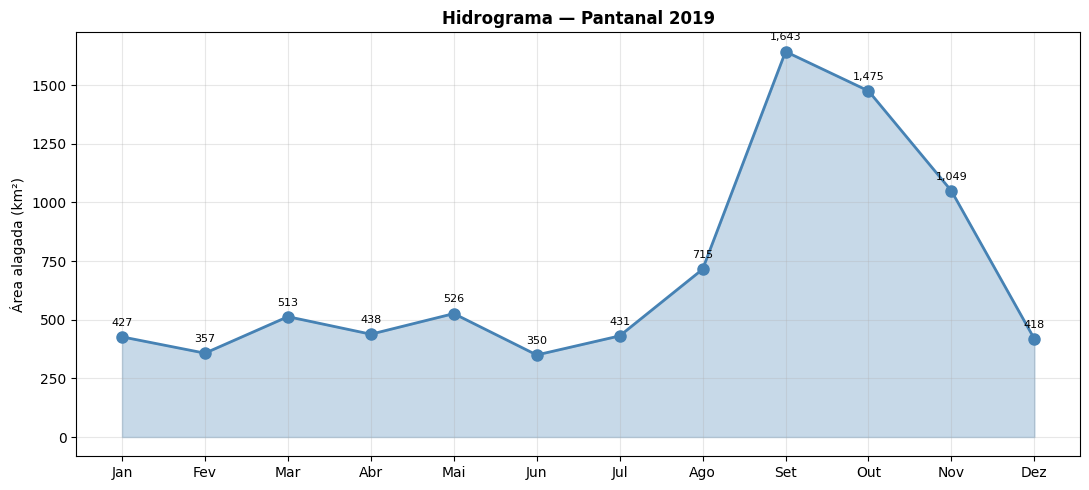

In [ ]:
# Gráfico do hidrograma
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(df['mes'], df['area_km2'], alpha=0.3, color='steelblue')
ax.plot(df['mes'], df['area_km2'], 'o-', linewidth=2, color='steelblue', markersize=8)

# Anota o valor em cima de cada ponto
for x, y in zip(df['mes'], df['area_km2']):
    ax.annotate(f'{y:,.0f}', (x, y), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=8)

ax.set_ylabel('Área alagada (km²)')
ax.set_title('Hidrograma — Pantanal 2019', fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PASTA_SAIDA}/fig_hidrograma.png', dpi=150, bbox_inches='tight')
plt.show()

**Como ler:** o hidrograma mostra o **pulso de inundação**. Picos no verão e mínimos no fim da seca são esperados pro Pantanal. A razão entre o pico e o mínimo (cheia / seca) é um indicador da amplitude do pulso anual.

## 13. Painel síntese

Juntando 4 dos produtos principais numa figura só, pra comparar:

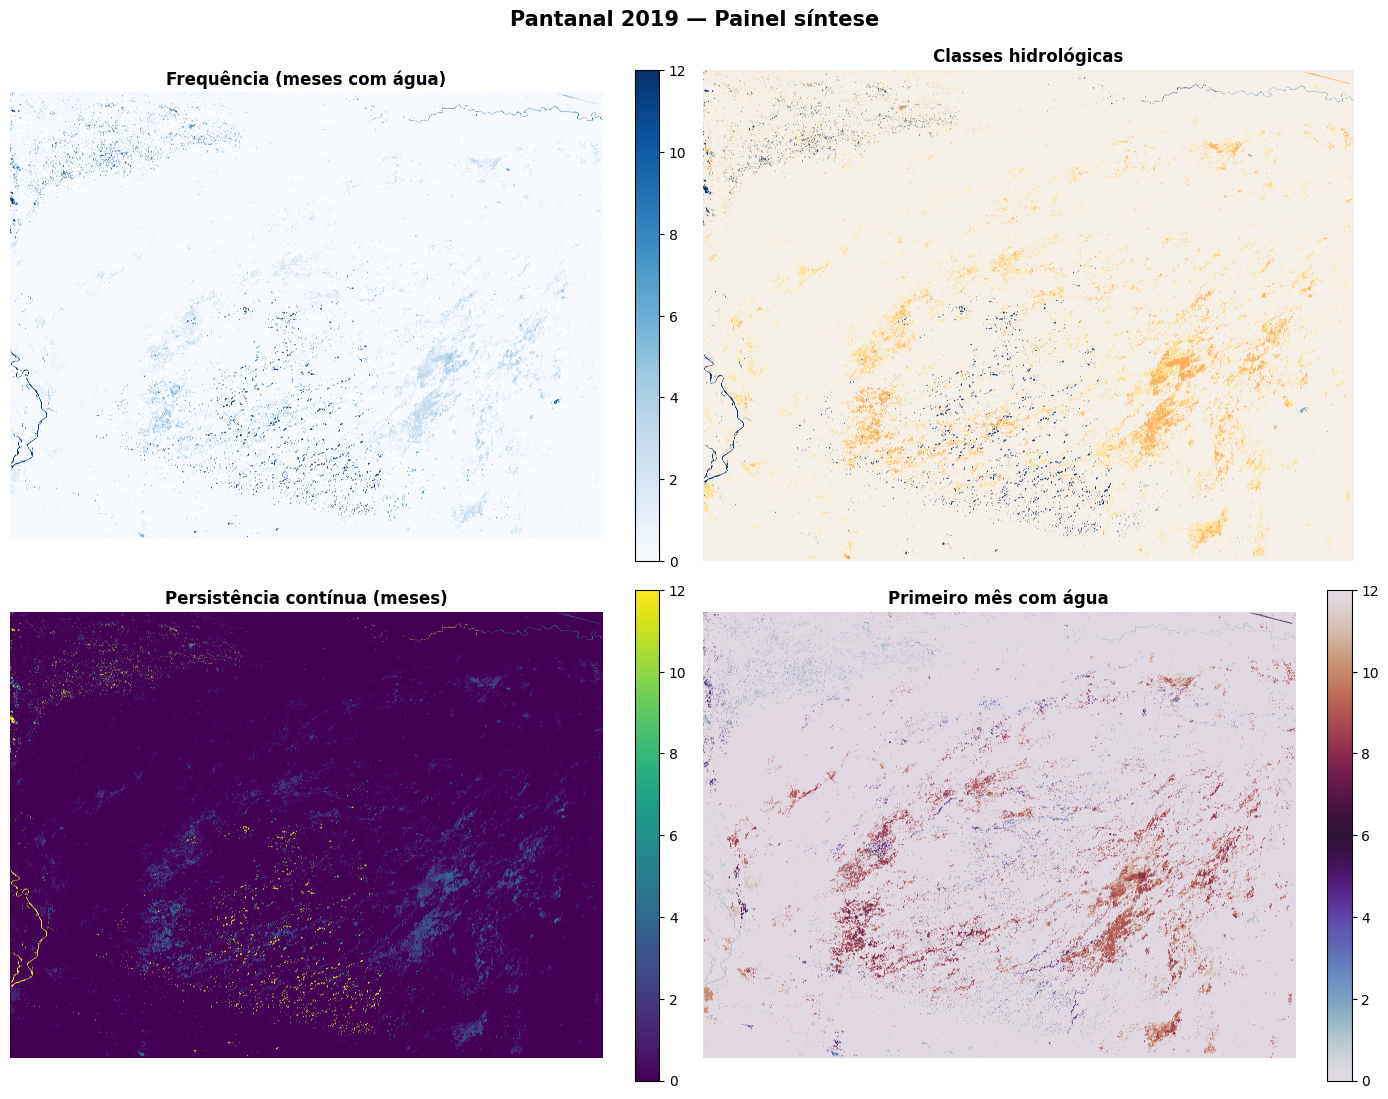

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

im0 = axes[0, 0].imshow(freq, cmap='Blues', vmin=0, vmax=12)
axes[0, 0].set_title('Frequência (meses com água)', fontweight='bold')
plt.colorbar(im0, ax=axes[0, 0], fraction=0.04)

cmap_cls = ListedColormap(['#f5f0e8', '#fee391', '#fdae61', '#74add1', '#08306b'])
axes[0, 1].imshow(classes, cmap=cmap_cls, vmin=0, vmax=4)
axes[0, 1].set_title('Classes hidrológicas', fontweight='bold')

im2 = axes[1, 0].imshow(persistencia, cmap='viridis', vmin=0, vmax=12)
axes[1, 0].set_title('Persistência contínua (meses)', fontweight='bold')
plt.colorbar(im2, ax=axes[1, 0], fraction=0.04)

im3 = axes[1, 1].imshow(primeiro, cmap='twilight', vmin=0, vmax=12)
axes[1, 1].set_title('Primeiro mês com água', fontweight='bold')
plt.colorbar(im3, ax=axes[1, 1], fraction=0.04, ticks=range(0, 13, 2))

for ax in axes.flat:
    ax.axis('off')
fig.suptitle('Pantanal 2019 — Painel síntese', fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig(f'{PASTA_SAIDA}/fig_painel_resumo.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Animação GIF (bônus 🎬)

Uma animação dos 12 meses ajuda a visualizar o pulso de inundação. É opcional mas costuma ficar bonito pra apresentações.

In [ ]:
import imageio.v2 as imageio

frames = []
for i in range(12):
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(stack[i], cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(f'{MESES_NOM[i]} 2019', fontsize=16, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()

    tmp = f'{PASTA_SAIDA}/_frame_{i:02d}.png'
    plt.savefig(tmp, dpi=100, bbox_inches='tight')
    plt.close()
    frames.append(imageio.imread(tmp))

caminho_gif = f'{PASTA_SAIDA}/animacao_2019.gif'
imageio.mimsave(caminho_gif, frames, fps=1, loop=0)

# Limpa frames temporários
for i in range(12):
    os.remove(f'{PASTA_SAIDA}/_frame_{i:02d}.png')

print(f'GIF salvo: {caminho_gif}')

# Exibe inline no notebook
from IPython.display import Image
Image(caminho_gif)

KeyboardInterrupt: 

Error in callback <function flush_figures at 0x7977003911c0> (for post_execute):


KeyboardInterrupt: 

## 15. Resumo das estatísticas

In [ ]:
total = freq.size
com_agua   = int((freq > 0).sum())
permanente = int((classes == 4).sum())

print('=' * 50)
print('  RESUMO — PANTANAL 2019')
print('=' * 50)
print(f'  Pixels totais:        {total:>12,}')
print(f'  Pixels com água:      {com_agua:>12,}  ({100*com_agua/total:.1f} %)')
print(f'  Pixels permanentes:   {permanente:>12,}  ({100*permanente/total:.1f} %)')
print()
print(f'  Mês com mais água:    {df.loc[df["area_km2"].idxmax(), "mes"]:>5}'
      f'  →  {df["area_km2"].max():>8,.0f} km²')
print(f'  Mês com menos água:   {df.loc[df["area_km2"].idxmin(), "mes"]:>5}'
      f'  →  {df["area_km2"].min():>8,.0f} km²')
print(f'  Razão cheia/seca:     {df["area_km2"].max() / max(df["area_km2"].min(), 1):.1f}×')
print()
print(f'  Persistência máxima:  {persistencia.max()} meses')
print(f'  Eventos de inundação máx por pixel: {eventos_inund.max()}')
print('=' * 50)

NameError: name 'freq' is not defined

## 16. Baixando os resultados

No Colab, dá pra zipar a pasta de resultados e baixar tudo de uma vez:

In [ ]:
# !zip -r /content/resultados_pantanal.zip /content/resultados
# from google.colab import files
# files.download('/content/resultados_pantanal.zip')

---

## ✅ Produtos gerados

Na pasta `resultados/` você terá:

**Rasters (GeoTIFF, abrem no QGIS/ArcGIS):**
- `frequencia_agua.tif` — meses com água (0–12)
- `classes_hidrologicas.tif` — classes 0–4
- `regime_cheia_seca.tif` — regime dominante
- `estacao_predominante.tif` — estação com mais água
- `persistencia_continua.tif` — maior sequência ininterrupta
- `eventos_inundacao.tif` / `eventos_seca.tif` — nº de transições
- `primeiro_mes.tif` / `ultimo_mes.tif` / `duracao_periodo.tif`

**Figuras (PNG):** mapas mensais, classes, hidrograma, painel síntese.

**Tabela:** `hidrograma.csv` com área alagada por mês.

**Animação:** `animacao_2019.gif`.

## 💡 Próximos passos

- **Análise multianual**: rodar pra cada ano da série e comparar (anos secos × anos de cheia extrema)
- **Recortar por sub-bacia** ou unidade de conservação com `rasterio.mask`
- **Comparar com dados de chuva** (CHIRPS, ERA5) → relação chuva × área alagada
- **Métricas de fragmentação** com `scikit-image` (`label`, `regionprops`) → tamanho médio de manchas, conectividade
- **Tendência temporal** com regressão linear pixel-a-pixel ao longo dos anos